In [14]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

from helpers.benchmark import load_records_from_directory, metric_for_benchmark, remove_cold_starts, trim_on_benchmark
from helpers.cpus import get_cpu_palette, shorten_cpu_name
from helpers.style import use_paper_style

LOG_DIR = "data/stage_a"
STAGE_A_CONFIG = [("aws", 512, "matmul"), ("azure", 512, "matmul"), ("gcp", 512, "matmul"), ("alibaba", 512, "matmul")]

PROVIDER_DISPLAY = {"aws": "AWS", "azure": "Azure", "gcp": "GCF", "alibaba": "Alibaba"}

REGION_SHORT = {
    "germanywestcentral": "germanywc",
    "southamerica-east1": "sa-east1",
}


df_raw = load_records_from_directory(LOG_DIR)

df = remove_cold_starts(df_raw)

df = df[df.apply(lambda row: (row["provider"], row["memory_size_mb"], row["benchmark_type"]) in STAGE_A_CONFIG, axis=1)]

trimmed_df = pd.DataFrame()
for config in STAGE_A_CONFIG:
    provider, memory_size_mb, benchmark_type = config
    regions = df[(df["provider"] == provider) & (df["memory_size_mb"] == memory_size_mb) & (df["benchmark_type"] == benchmark_type)]["region"].unique()
    for region in regions:
        df_subset = df[(df["provider"] == provider) & (df["memory_size_mb"] == memory_size_mb) & (df["benchmark_type"] == benchmark_type) & (df["region"] == region)]
        trimmed_config_region_df = trim_on_benchmark(df_subset, group_on_timestamp=False, benchmark=benchmark_type)
        trimmed_df = pd.concat([trimmed_df, trimmed_config_region_df], ignore_index=True)

print("raw rows:", len(df_raw))
print("region-clean rows:", len(df))

print("trimmed rows:", len(trimmed_df))

raw rows: 324863
region-clean rows: 83541
trimmed rows: 82647


Saved: plots/stage_a/composition_all_providers.pdf


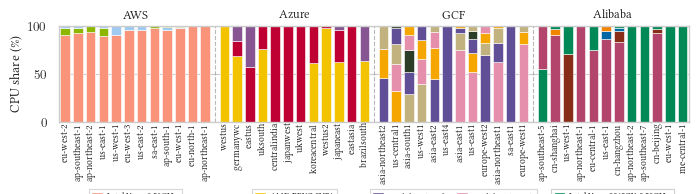

In [16]:
def plot_composition_all_providers(
    df: pd.DataFrame,
    trimmed_df: pd.DataFrame,
    providers: list[str] = ["aws", "azure", "gcp", "alibaba"],
    memory_size: int = 512,
    benchmark_type: str = "matmul",
    out_dir: str = "plots/stage_a",
    show: bool = True,
):
    use_paper_style()
    metric = metric_for_benchmark(benchmark_type)

    all_bars = []
    all_cpu_types = {}

    for provider in providers:
        df_prov = df[
            (df["provider"] == provider)
            & (df["memory_size_mb"] == memory_size)
            & (df["benchmark_type"] == benchmark_type)
        ].copy().dropna(subset=[metric, "cpu_type", "region"])

        df_trim = trimmed_df[
            (trimmed_df["provider"] == provider)
            & (trimmed_df["memory_size_mb"] == memory_size)
            & (trimmed_df["benchmark_type"] == benchmark_type)
        ].copy()

        stats = df_trim.groupby("region")[metric].agg(mean="mean", std="std")
        stats["cv"] = (stats["std"] / stats["mean"]) * 100.0

        comp = df_prov.groupby(["region", "cpu_type"]).size().unstack(fill_value=0)
        comp = comp.div(comp.sum(axis=1), axis=0) * 100.0

        regions_sorted = stats.sort_values("cv", ascending=False).index.tolist()
        all_cpu_types[provider] = sorted(df_prov["cpu_type"].unique())

        for region in regions_sorted:
            shares = {}
            if region in comp.index:
                shares = comp.loc[region].to_dict()
            all_bars.append({
                "provider": provider,
                "region": region,
                "cv": stats.loc[region, "cv"] if region in stats.index else 0,
                "shares": shares,
            })

    x = []
    x_pos = 0
    group_starts = {}
    group_ends = {}
    separator_positions = []

    for i, bar in enumerate(all_bars):
        prov = bar["provider"]
        if prov not in group_starts:
            if i > 0:
                separator_positions.append(x_pos - 0.25)
                x_pos += 0.5
            group_starts[prov] = x_pos
        x.append(x_pos)
        group_ends[prov] = x_pos
        x_pos += 1

    x = np.array(x)

    provider_palettes = {}
    for provider in providers:
        provider_palettes[provider] = get_cpu_palette(
            all_cpu_types[provider], provider=provider
        )

    fig, ax = plt.subplots(figsize=(7.0, 1.25))
    fig.subplots_adjust(left=0.06, right=0.96)

    provider_legend_handles = {p: {} for p in providers}
    extra_artists = []

    for i, bar in enumerate(all_bars):
        bottom = 0
        provider = bar["provider"]
        palette = provider_palettes[provider]

        sorted_cpus = sorted(bar["shares"].items(), key=lambda kv: -kv[1])

        for cpu_type, share in sorted_cpus:
            if share <= 0:
                continue
            color = palette.get(cpu_type, "#7f8c8d")

            ax.bar(
                x[i], share, bottom=bottom, width=0.75,
                color=color, edgecolor="white", linewidth=0.4
            )
            bottom += share

            if cpu_type not in provider_legend_handles[provider]:
                provider_legend_handles[provider][cpu_type] = (
                    Patch(facecolor=color, edgecolor="white", linewidth=0.3),
                    shorten_cpu_name(cpu_type),
                )

    ax.set_xticks(x)
    ax.set_xticklabels(
        [REGION_SHORT.get(bar["region"], bar["region"]) for bar in all_bars],
        rotation=90, ha="center", fontsize=7,
    )
    ax.tick_params(axis="x", pad=1, length=0)

    for provider in providers:
        mid = (group_starts[provider] + group_ends[provider]) / 2
        txt = ax.text(
            mid, 105, PROVIDER_DISPLAY.get(provider, provider.upper()),
            ha="center", va="bottom",
            fontweight="bold",
        )
        extra_artists.append(txt)

    for sep_x in separator_positions:
        ax.axvline(sep_x, color="#888888", linewidth=0.8, linestyle="--", alpha=0.6)

    ax.set_ylim(0, 100)
    ax.set_ylabel("CPU share (\\%)", fontweight="bold")
    ax.set_xlim(-0.5, x[-1] + 0.5)

    fig.canvas.draw()
    labels_bottom = min(t.get_window_extent().y0 for t in ax.get_xticklabels())
    legend_y = ax.transAxes.inverted().transform((0, labels_bottom))[1] - 0.01

    xlim = ax.get_xlim()
    x_range = xlim[1] - xlim[0]
    for provider in providers:
        handles_dict = provider_legend_handles[provider]
        if not handles_dict:
            continue

        handles = [h for h, _ in handles_dict.values()]
        labels = [l for _, l in handles_dict.values()]

        anchor_x_data = (group_starts[provider] + group_ends[provider]) / 2
        anchor_x_norm = (anchor_x_data - xlim[0]) / x_range
        group_width = (ax.transData.transform((group_ends[provider] + 0.5, 0))[0]
                       - ax.transData.transform((group_starts[provider] - 0.5, 0))[0])

        for ncol in ([2, 1] if len(labels) > 3 else [1]):
            leg = ax.legend(
                handles, labels,
                loc="upper center",
                bbox_to_anchor=(anchor_x_norm, legend_y),
                fontsize=6.5,
                ncol=ncol,
                columnspacing=0.8,
                frameon=True,
                edgecolor="#cccccc",
                fancybox=False,
                handlelength=1.2,
                handletextpad=0.4,
                labelspacing=0.3,
            )
            fig.canvas.draw()
            if leg.get_window_extent().width <= group_width + 28:
                break
        ax.add_artist(leg)
        extra_artists.append(leg)

    os.makedirs(out_dir, exist_ok=True)
    out_file = f"{out_dir}/composition_all_providers.pdf"
    fig.savefig(out_file, dpi=300, bbox_inches="tight", bbox_extra_artists=extra_artists)
    print(f"Saved: {out_file}")

    if show:
        plt.show()
    else:
        plt.close(fig)


plot_composition_all_providers(df, trimmed_df, show=True)